# Step 3 – Descriptive and diagnostic analytics (EDA)
**Urban home-farming start-up (India) · synthetic data**

This notebook answers one question in four stages: **will this business sell, and how should its sales pipeline be built?**

| Section | Data | Type of analytics | Question |
|---|---|---|---|
| 1 | Survey (2,940) | Descriptive – *what is happening* | Who are the customers, what do they want, what will they pay? |
| 2 | Survey | Diagnostic – *why* | What drives intent, willingness to pay and subscription? |
| 3 | Pilot CRM (4,200 leads) | Descriptive | How did leads flow through the funnel? |
| 4 | Pilot CRM | Diagnostic | Why do some leads buy and stay while others do not? |
| 5 | Both | End-to-end validation | Did what customers *said* match what they *did*? Which pipeline should be finalised? |

Every chart is followed by three short paragraphs: **What it shows** (the facts), **Why** (the diagnosis) and
**So what** (the business decision). The numbers inside the text are computed from the data, not typed in, so they
always match the chart. The calculations live in `analytics.py`; the drawing code is in `charts.py`.

**Methods used:** frequency and percentage tables, medians and quartiles, histograms and box plots, Spearman rank
correlation (for ordered survey scales), Pearson correlation with a linear trend, 95% Wilson confidence intervals
for rates, chi-square tests of independence, a randomised price test (A/B), and Kaplan-Meier survival for subscribers.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown, Image
import analytics as A, charts as C

s, p = A.load()
FIG = 0
def show(res):
    """Draw a result, save it to figures/ for the report, and print its explanation."""
    global FIG; FIG += 1
    fig = C.mpl(res); path = f"figures/{FIG:02d}_{res['id']}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight"); plt.close(fig)
    display(Markdown(f"### {res['id'].upper()}. {res['title']}\n*Question: {res['question']}*"))
    display(Image(path, width=760))
    t = res["text"]
    display(Markdown(f"**What it shows.** {t['shows']}\n\n**Why.** {t['why']}\n\n**So what.** {t['so_what']}"))
print(f"survey {s.shape}, pipeline {p.shape}")

survey (2940, 70), pipeline (4200, 43)


## 1. Survey – descriptive analytics
### 1.0 Summary statistics
Central tendency and spread for the main numeric answers. Medians are quoted alongside means because rupee
amounts are rarely symmetric.

In [2]:
num = s[["household_size", "veg_spend", "spend_per_person", "wtp_system", "wtp_refill", "att_health", "att_eco", "att_tech",
         "att_time_poor", "att_hobby", "intent_score", "subscribe_score"]]
desc = num.describe(percentiles=[.25, .5, .75]).T.rename(columns={"50%": "median"})
desc["missing"] = num.isna().sum()
desc[["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max"]].round(1)

,count,missing,mean,std,min,25%,median,75%,max
household_size,2940.0,0,3.5,1.3,1.0,3.0,4.0,4.0,8.0
veg_spend,2940.0,0,6370.2,1579.6,1500.0,5000.0,6100.0,7500.0,12000.0
spend_per_person,2940.0,0,2102.6,1087.7,700.0,1500.0,1750.0,2333.0,9100.0
wtp_system,2819.0,121,4325.5,2052.3,0.0,3000.0,4500.0,6000.0,10000.0
wtp_refill,2786.0,154,285.3,120.4,0.0,200.0,300.0,350.0,700.0
att_health,2940.0,0,3.7,1.0,1.0,3.0,4.0,4.0,5.0
att_eco,2940.0,0,3.6,1.0,1.0,3.0,4.0,4.0,5.0
att_tech,2940.0,0,3.4,1.1,1.0,3.0,3.0,4.0,5.0
att_time_poor,2940.0,0,3.5,1.1,1.0,3.0,4.0,4.0,5.0
att_hobby,2940.0,0,3.3,1.0,1.0,3.0,3.0,4.0,5.0


**Reading the table.** The typical household has 3–4 people and spends about ₹6,000 a month on vegetables and herbs.
The median maximum price for a starter kit is ₹4,500 and for a monthly refill ₹300. Attitude scores average above
the midpoint (3) for health and eco motives – the 'green' sentiment is real – while average purchase intent sits
below the midpoint, which is normal for a new product category.

### D1. Who answered: growing space by city tier
*Question: Do customers in different cities have room for a growing system?*

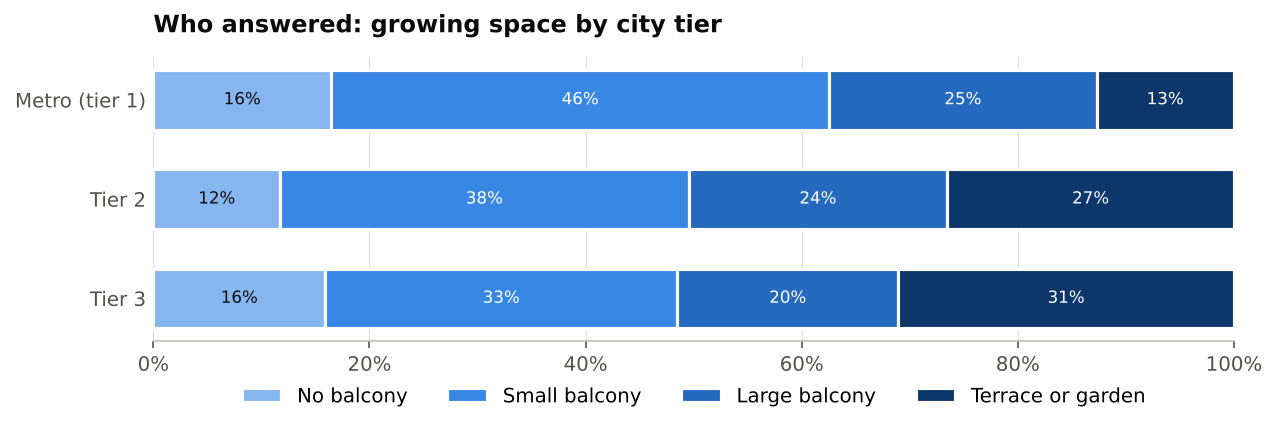

**What it shows.** 2,940 usable responses: 1,824 from metros, 852 from tier-2 and 264 from tier-3 cities. Each bar splits one city tier by the space people have to grow in.

**Why.** 63% of metro respondents have only a window sill or a small balcony, against 48% in tier-3 cities, where terraces and independent houses are common. Space is scarce exactly where incomes and online buying are highest.

**So what.** The product must work in under 40 sq ft to sell in metros - a vertical, balcony-rail format, not a raised bed. Tier-3 households have space but, as later charts show, lower budgets.

In [3]:
show(A.d1_profile(s))

### D2. Purchase intent at the price shown
*Question: How many people say they would buy?*

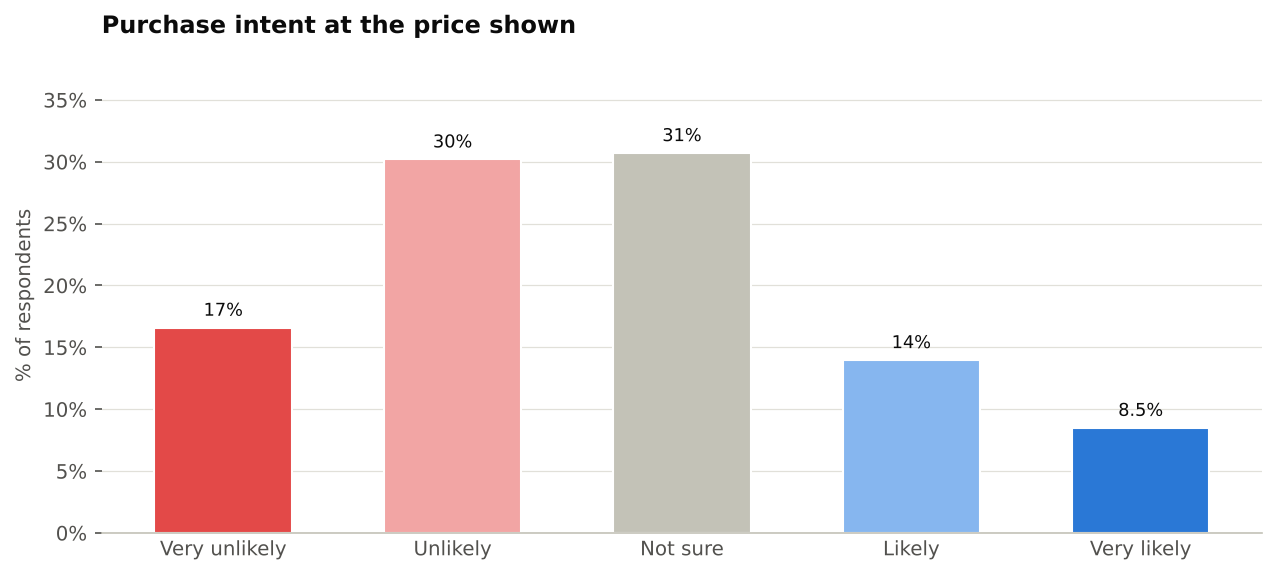

**What it shows.** Answers to Q15 ("How likely are you to buy at ₹X?"). Top-2-box (Likely + Very likely) = 22%; bottom-2-box = 47%; 31% are not sure.

**Why.** Each respondent saw one randomly chosen price between ₹2,999 and ₹9,999, so this mixes cheap and expensive offers. Stated intent is also known to overstate real buying - people say "likely" to be agreeable.

**So what.** About 22 in 100 people are positive: a real but niche market. The "Not sure" block is the group demos and trials must convert; it is larger than the committed buyers.

In [4]:
show(A.d2_intent(s))

### D3. Maximum price people would pay for a starter kit
*Question: What price can the market bear?*

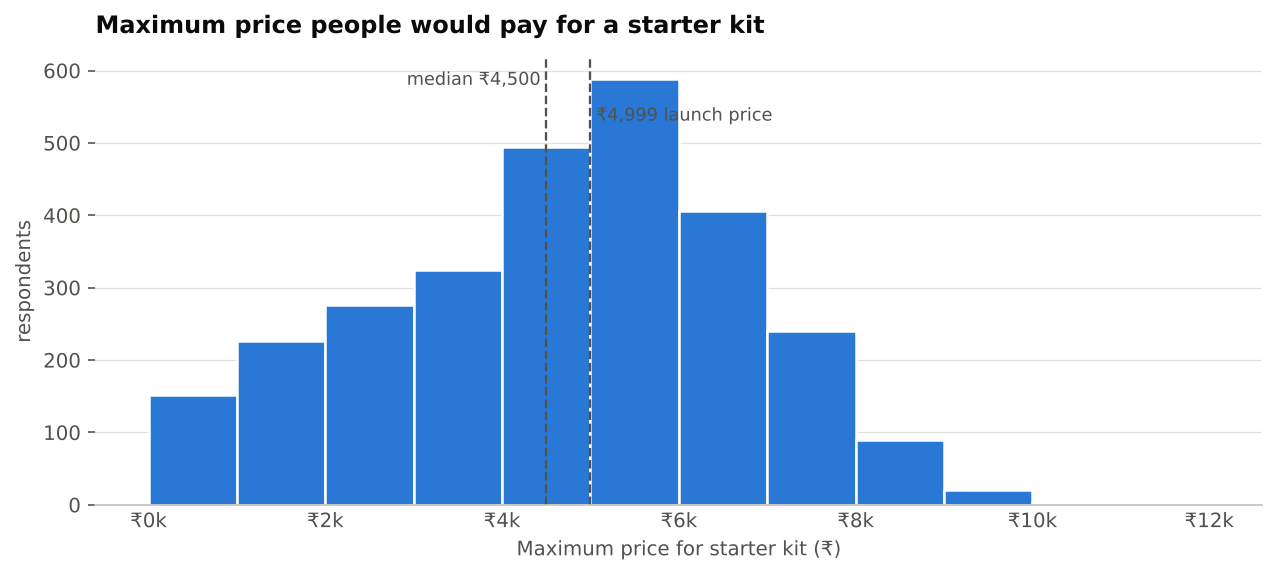

**What it shows.** Distribution of Q16a for 2,819 people who answered. Median ₹4,500, mean ₹4,326. 48% would pay ₹4,999 or more; 27% would pay ₹5,999 or more.

**Why.** Spikes at round numbers (₹3,000, ₹5,000) are normal - people type round amounts. The mean sits close to the median after the extra-zero typos were removed in cleaning, so the distribution is close to symmetric.

**So what.** A ₹4,999 kit is within budget for only about 48% of the market; every ₹1,000 above that loses a large share. A cheaper entry kit (₹2,999-3,999) would open the larger group whose limit sits around ₹4,500.

In [5]:
show(A.d3_wtp(s))

### D4. Features customers want
*Question: What should the product include?*

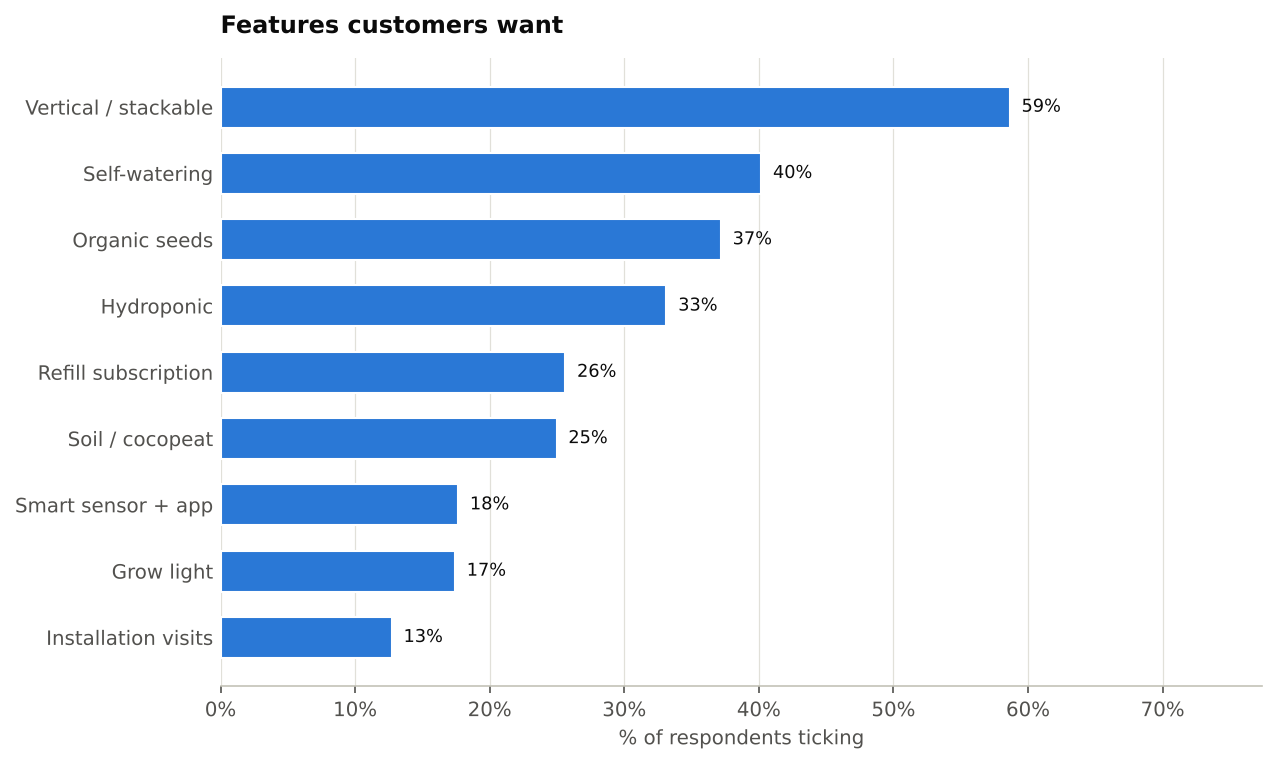

**What it shows.** Share of respondents ticking each feature in Q12 (they could tick several; average 2.7). Top three: Vertical / stackable (59%), Self-watering (40%), Organic seeds (37%).

**Why.** The most-ticked features remove effort or save space - the two biggest barriers in a flat. Tech features (smart sensor) and services (installation) appeal to a smaller, richer group.

**So what.** The base kit should be vertical and self-watering. The smart sensor (18%) belongs in an add-on, not the base price. Only 26% ask for a subscription unprompted, so the refill must be sold on convenience, not assumed.

In [6]:
show(A.d4_features(s))

### D5. Biggest worries about growing at home
*Question: What stops people from buying?*

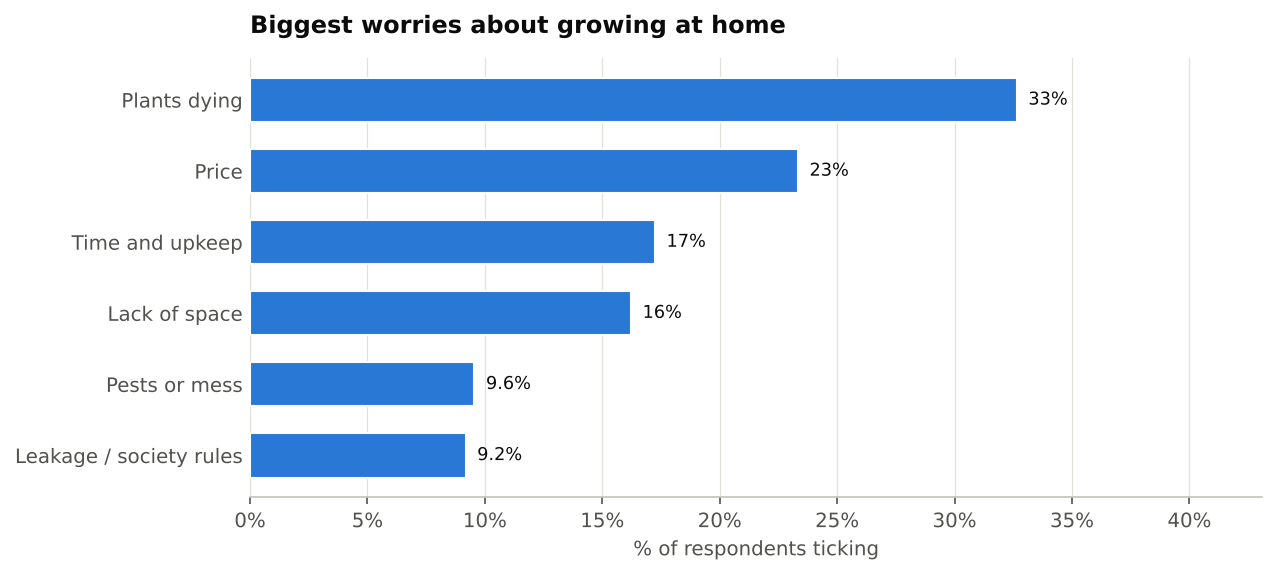

**What it shows.** Share ticking each worry in Q14 (up to two). Top worries: Plants dying (33%) and Price (23%). 25% ticked no worry at all.

**Why.** "Plants dying" is a fear learned from failure: 43% of people who tried growing and gave up tick it, against 28% of everyone else. Price worry is income-driven: 35% of households under ₹1 lakh a month tick it, against 13% above.

**So what.** Marketing should promise a result, not a product: a guaranteed first harvest, pre-seeded pods and a replace-if-it-dies policy answer the top fear directly and cost little.

In [7]:
show(A.d5_worries(s))

### D6. Did people who tried growing keep it up for 6 months?
*Question: How big is the drop-off risk after purchase?*

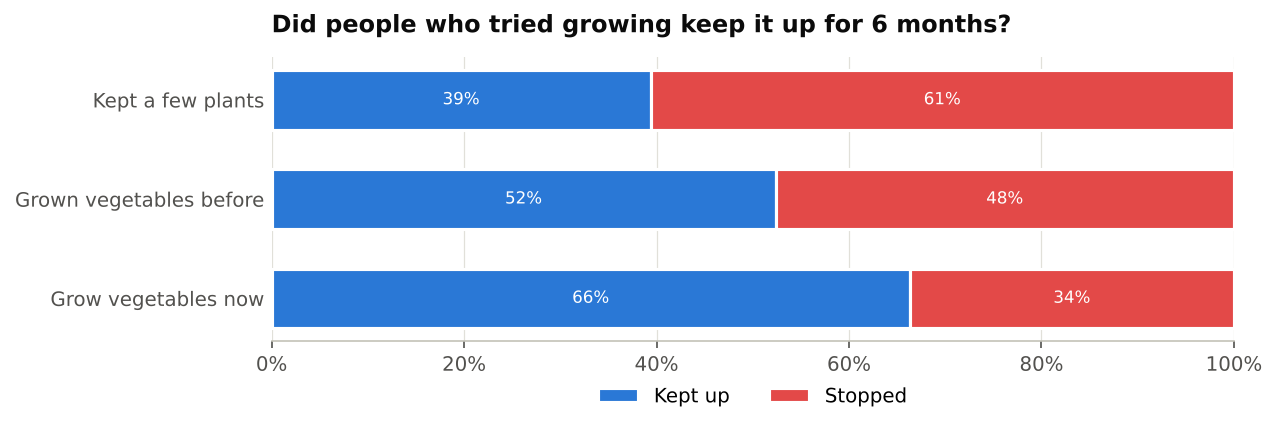

**What it shows.** Among 1,836 respondents who have tried growing (Q10-Q11), 47% kept it up for six months or more; 53% stopped.

**Why.** Light gardeners ("kept a few plants") stopped 61% of the time, people who grow vegetables now only 34%: the habit, not the equipment, is what lasts. Losing about half of starters within six months is typical of hobby products.

**So what.** If subscribers behave like this, monthly churn would be about 11.8% - a refill customer would last only ~8 months. The pilot tests whether onboarding and refills can do better.

In [8]:
show(A.d6_kept_up(s))

## 2. Survey – diagnostic analytics (correlation-based)
Descriptive charts say *what*; these charts look for *why* by relating answers to each other.
Correlation is not causation – with one important exception: the kit price (Q15) and refill price (Q17) were
**assigned at random**, so differences across prices are caused by price.

### G1. Correlation matrix of survey answers
*Question: Which answers move together?*

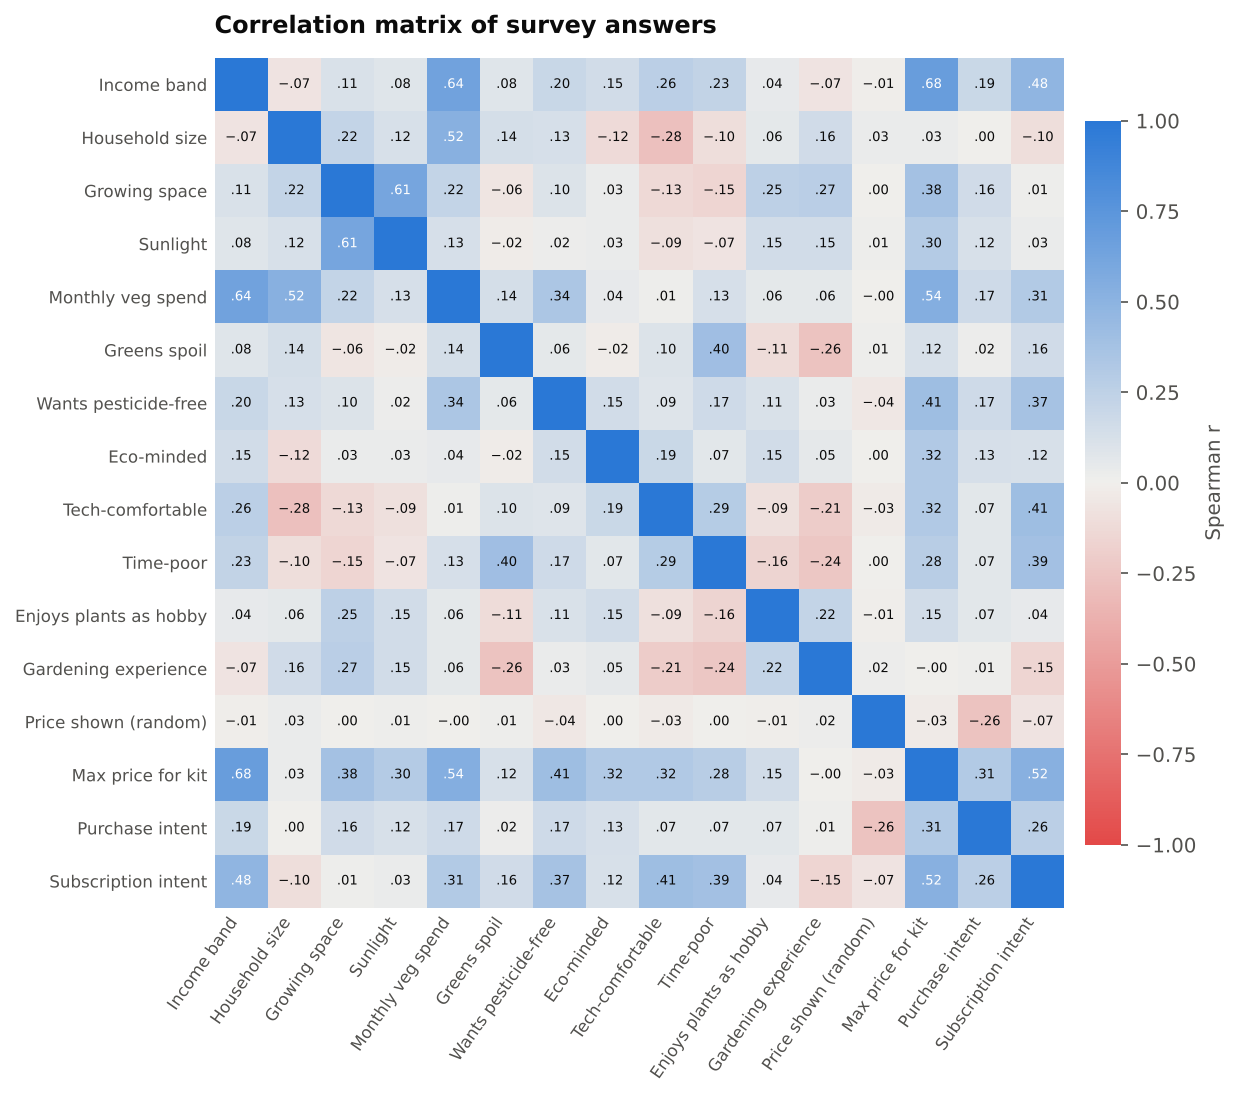

**What it shows.** Spearman rank correlation between every pair of numeric answers (+1 = rise together, -1 = one rises as the other falls, 0 = no link). Spearman is used because most answers are ordered scales, not true numbers.

**Why.** Strongest pairs: Income band & Max price for kit (+0.68); Income band & Monthly veg spend (+0.64); Growing space & Sunlight (+0.61). Income, space and spend cluster together (richer households have bigger homes and bigger food bills), so their separate effects overlap. Price shown was assigned at random, so its correlation with intent is causal, not coincidence.

**So what.** Among the factors that could drive it, purchase intent links most strongly with income band (+0.19) and wants pesticide-free (+0.17), and falls with price shown (random) (-0.26). The next chart ranks every driver.

In [9]:
show(A.g1_corr(s))

### G2. What drives purchase intent?
*Question: Which customer traits predict a 'yes'?*

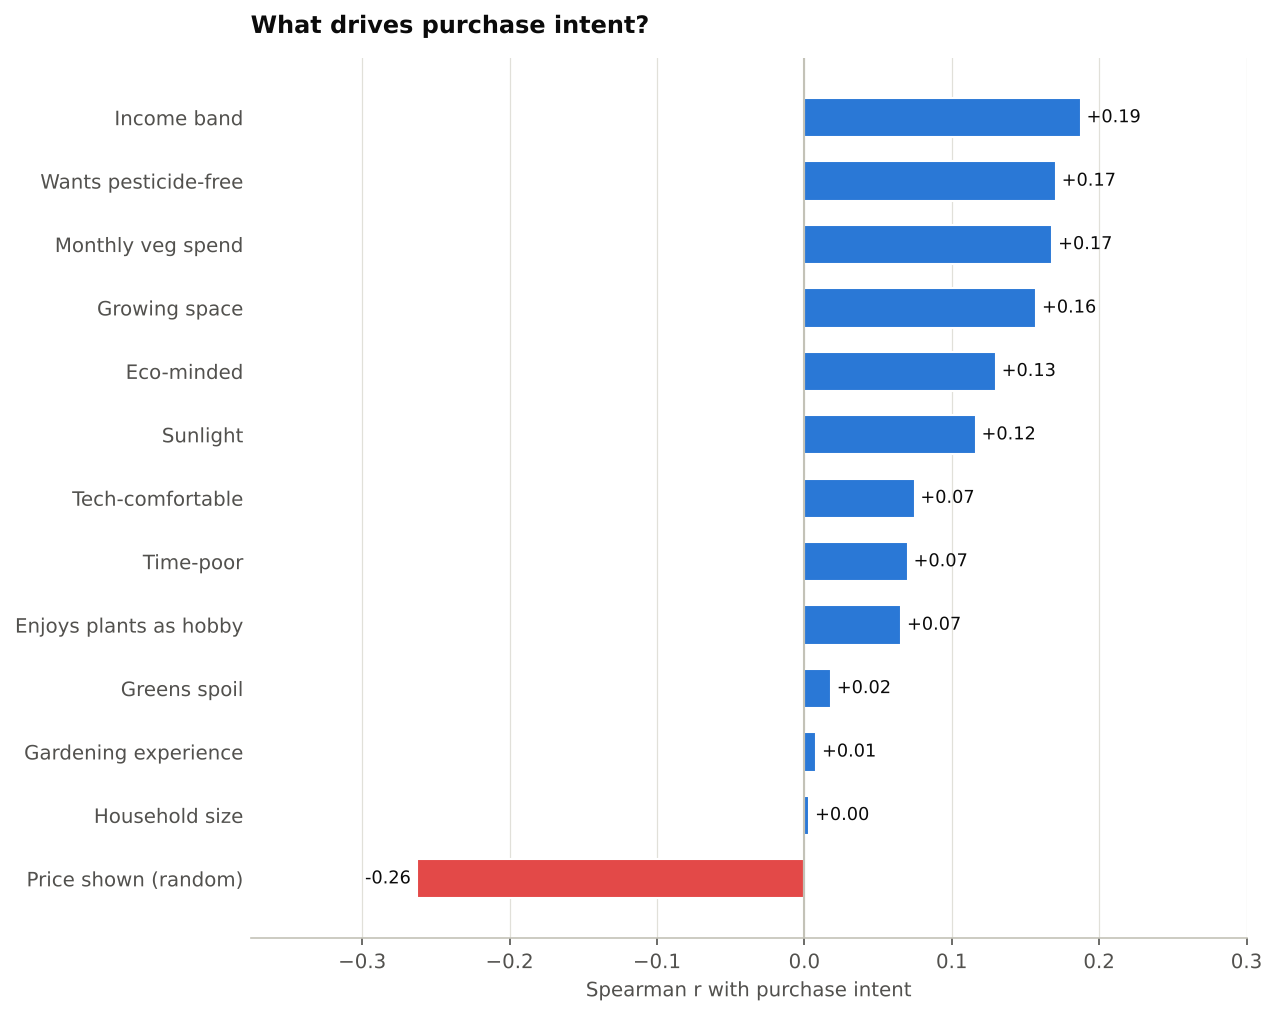

**What it shows.** Each bar is the rank correlation of one factor with purchase intent (1-5). Blue bars raise intent, red bars lower it.

**Why.** The strongest positive signals are income band (+0.19), wants pesticide-free (+0.17) and monthly veg spend (+0.17); attitudes sit alongside income, not behind it. The price shown has the strongest negative link (-0.26) - and because it was randomised, higher price causes lower intent. Weak or no link: household size, gardening experience, greens spoil.

**So what.** Target households that combine budget with the right attitude - health-conscious, eco-minded, with a balcony - e.g. organic-store shoppers and society gardening groups. Price is the biggest single lever the company controls.

In [10]:
show(A.g2_drivers(s))

### G3. Price test: intent falls as price rises
*Question: How sensitive is demand to price?*

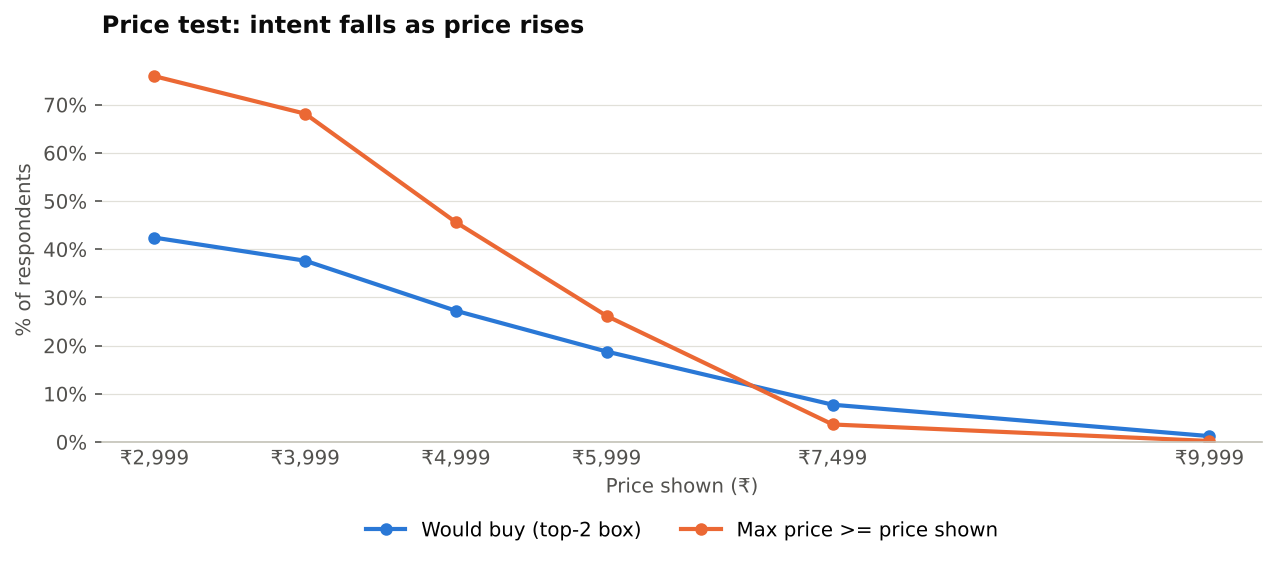

**What it shows.** Each respondent saw one random price. At ₹2,999 42% would buy; at ₹9,999 only 1%. The second line is the share whose stated maximum price covers the price shown. Difference across prices is statistically significant (p < 0.001).

**Why.** Both lines fall together - intent drops because the price passes people's budget, not because they dislike the product. The gap between the lines shows some people would 'like' to buy at a price above what they said they'd pay.

**So what.** Moving from ₹4,999 to ₹5,999 cuts intent from 27% to 19%. Revenue per 100 respondents peaks at ₹3,999 - but profit also depends on unit cost and acquisition cost, so the pilot tests ₹4,999-5,999 in the field.

,price (₹),would buy %,can afford %,n,revenue per 100 people (₹)
0,2999,42.4,75.9,488,127212.0
1,3999,37.6,68.1,489,150474.0
2,4999,27.2,45.6,492,136152.0
3,5999,18.8,26.2,490,112634.0
4,7499,7.7,3.6,491,58037.0
5,9999,1.2,0.2,490,12244.0


In [11]:
show(A.g3_price(s))
display(A.g3_price(s)["table"].assign(would_buy=lambda x: (x.would_buy * 100).round(1), afford=lambda x: (x.afford * 100).round(1),
                                     rev100=lambda x: x.rev100.round(0)).rename(columns={"price_shown": "price (₹)", "would_buy": "would buy %",
                                     "afford": "can afford %", "rev100": "revenue per 100 people (₹)"}))

### G4. Maximum kit price by income band
*Question: Does income explain willingness to pay?*

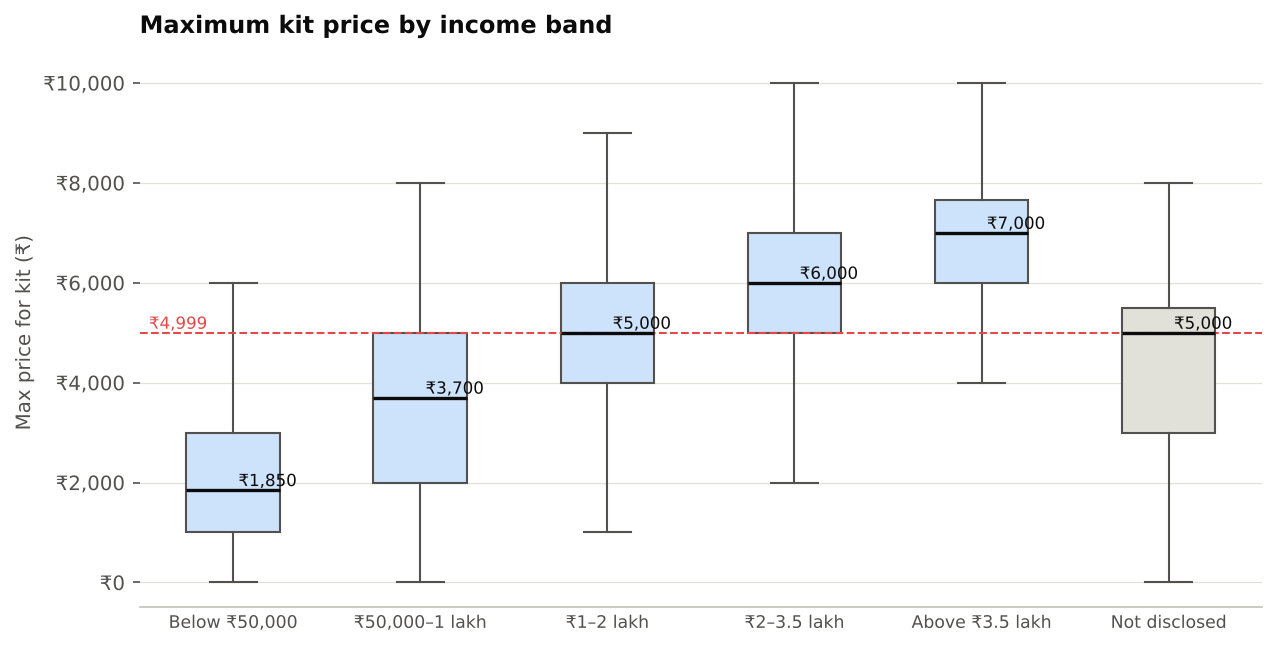

**What it shows.** Box = middle 50% of answers, line = median, whiskers = typical range. Median max price rises from ₹1,850 in the lowest band to ₹7,000 in the highest (Spearman r = +0.68, p < 0.001).

**Why.** Income sets the budget ceiling, but the boxes overlap a lot: attitude and space explain the rest. People who did not disclose income have a median of ₹5,000, close to the middle bands - so leaving them out would not bias results much.

**So what.** A ₹4,999 kit sits at or above the median for households earning under ₹1 lakh a month. Lead targeting should focus on ₹1 lakh+ households, or an EMI / cheaper kit is needed for the rest.

In [12]:
show(A.g4_wtp_income(s))

### G5. Purchase intent by growing space
*Question: Does more space mean more buyers?*

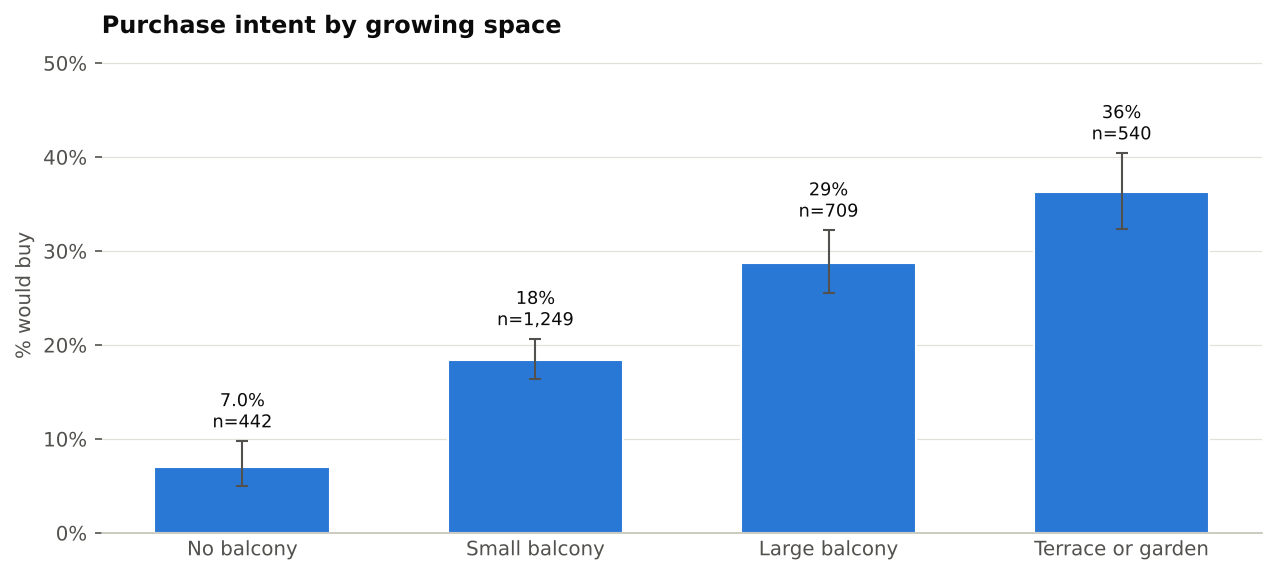

**What it shows.** Share who would buy (top-2 box) in each space group, with 95% confidence intervals. It rises from 7% (no balcony) to 36% (terrace or garden); p < 0.001.

**Why.** More space means more light and more room to grow a meaningful amount of food, so the product's value is higher. Space also tracks income, so part of this gap is an income effect.

**So what.** Window-sill households are the weakest segment and should not be the launch target; large-balcony and terrace homes in gated societies are, which supports housing-society demos as a channel.

In [13]:
show(A.g5_space(s))

### G6. Monthly vegetable spend vs maximum kit price
*Question: Do bigger food spenders value the kit more?*

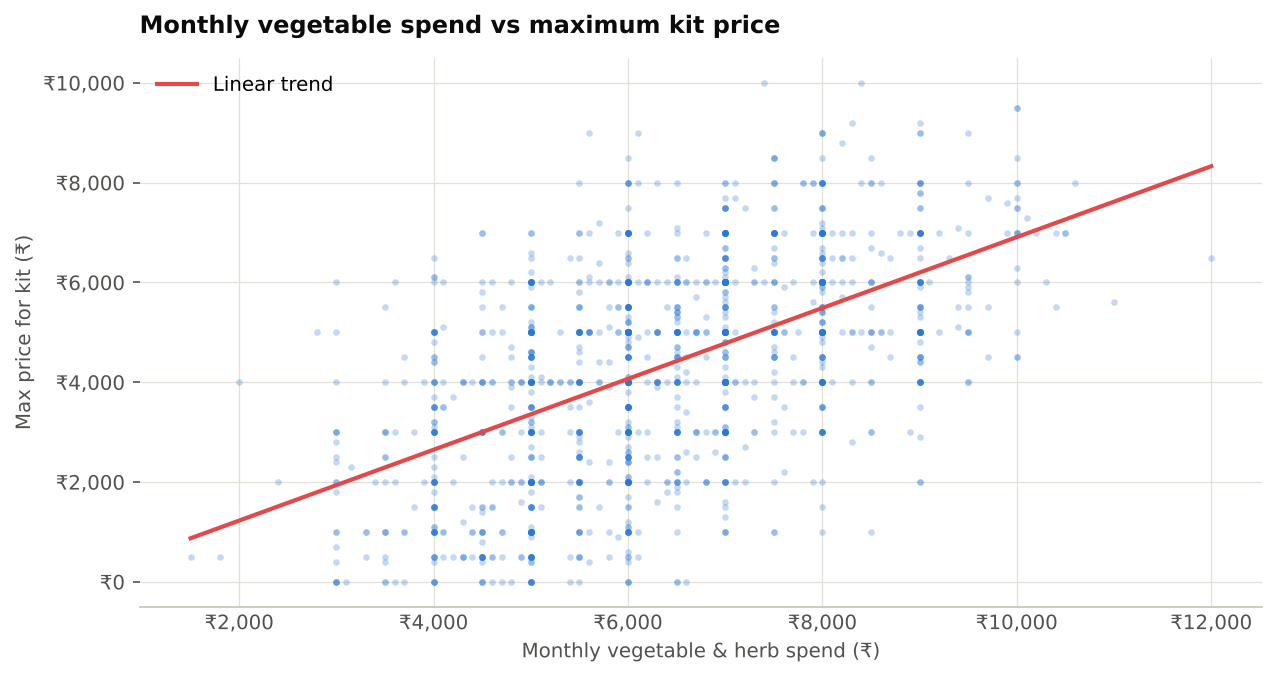

**What it shows.** Each dot is one respondent (sample of 1,500). Pearson r = +0.55 (p < 0.001); the trend line says each extra ₹1,000 of monthly vegetable spend goes with ₹710 more willingness to pay.

**Why.** Families who spend more on fresh produce see more value in growing some of it, and they are usually richer. The wide scatter shows spend is only a moderate predictor - attitude matters as much.

**So what.** Monthly vegetable spend is a useful screening question for sales calls and a credible value message ("save on the herbs and greens you already buy").

In [14]:
show(A.g6_wtp_spend(s))

### G7. Refill subscription intent by price and time pressure
*Question: Will customers pay monthly, and who?*

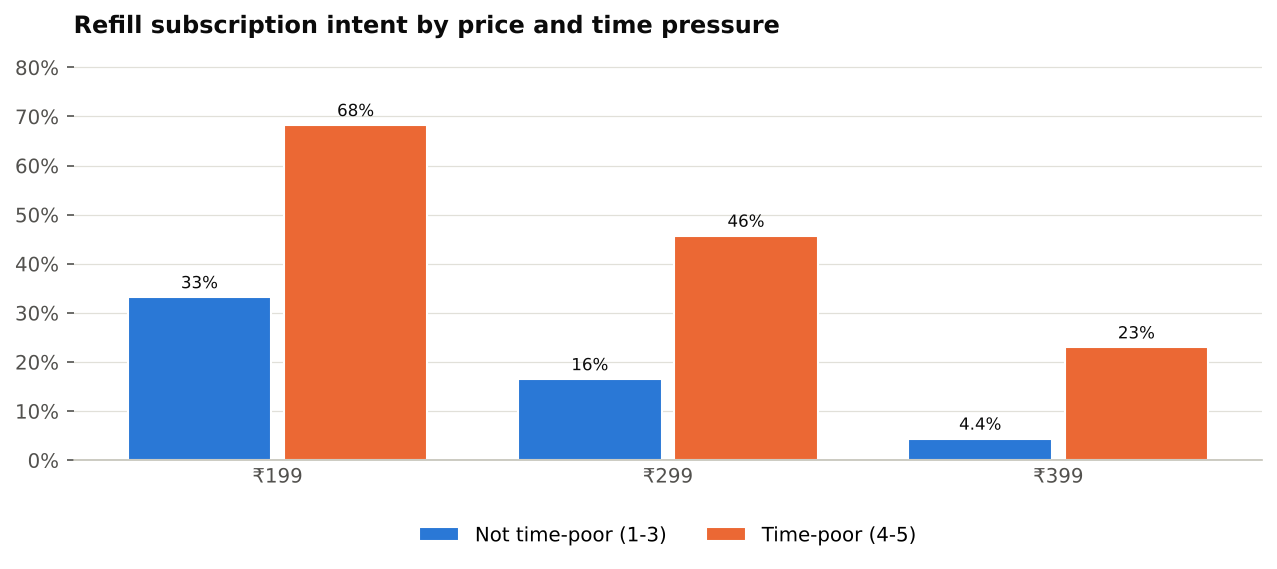

**What it shows.** Share saying they would probably or definitely subscribe, by refill price shown (random) and by how time-poor they are. Overall: 50% at ₹199, 31% at ₹299, 14% at ₹399 (p < 0.001).

**Why.** Time-poor households are about 28 points more willing at every price: a refill that arrives ready to plant saves them effort, which is what they pay for. Price matters, but less than for the kit.

**So what.** Monthly revenue per 100 people is ₹10,021 at ₹199, ₹9,296 at ₹299 and ₹5,694 at ₹399. After GST, seeds and shipping (about ₹135 a box), contribution is ₹2,459 at ₹199 vs ₹4,391 at ₹299, so ₹299 is the better price; ₹399 loses too many people. Sell the subscription to busy dual-income households as 'never think about seeds again'. Stated intent is optimistic; the pilot measures the real rate.

In [15]:
show(A.g7_subscribe(s))

### G8. Which features separate likely buyers from the rest?
*Question: Which features should the pitch lead with?*

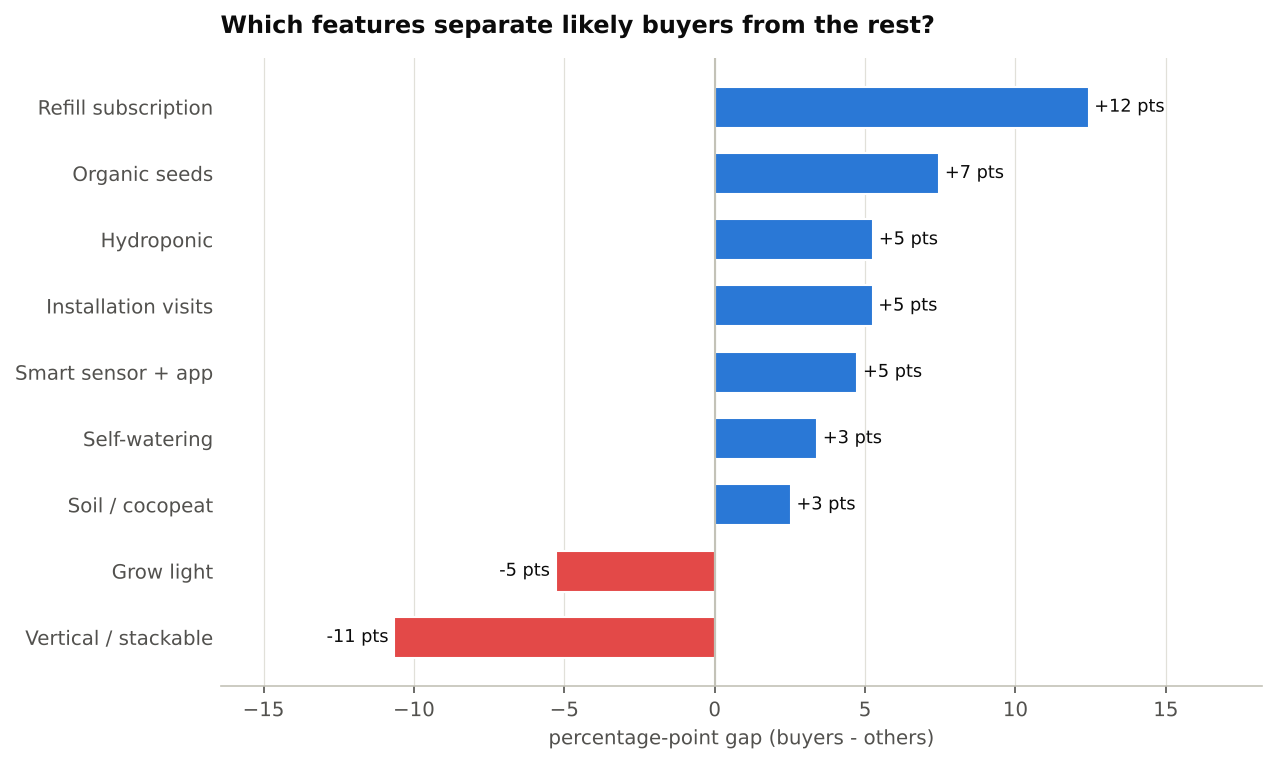

**What it shows.** Percentage-point difference in how often likely buyers (661) and others (2,279) tick each feature. Largest gaps: Refill subscription (+12 pts) and Organic seeds (+7 pts).

**Why.** A feature everybody wants (high in the feature-demand chart) but with a small gap here is a hygiene factor - expected, not persuasive. A feature with a big gap is what excited buyers are looking for.

**So what.** Lead the pitch with refill subscription and organic seeds. Negative gaps (vertical / stackable, grow light) are features wanted mainly by households with little space or light - 79% of window-sill and small-balcony homes want a vertical system against 31% of others - and those households buy least. They are still needed in the product for metros, but they will not sell it on their own.

In [16]:
show(A.g8_feature_lift(s))

## 3. Pilot sales pipeline – descriptive analytics
After the survey, a hypothetical 6-month pilot (January–June 2027, Bengaluru and Pune) sold the kit through six
channels. Every lead was logged in a CRM from first contact to refill subscription.

In [17]:
k = pd.Series({
    "Leads": f"{len(p):,}", "Buyers": f"{int(p.purchased.sum()):,}", "Lead-to-sale": A.pct(p.purchased.mean(), 1),
    "Average order value (incl. GST)": A.inr(p.order_value_inr.mean()), "Revenue (incl. GST)": A.inr(p.order_value_inr.sum()),
    "Marketing spend": A.inr(p.acquisition_cost_inr.sum()), "Blended CAC": A.inr(p.acquisition_cost_inr.sum() / p.purchased.sum()),
    "Median days lead → purchase": f"{p.days_to_close.median():.0f}", "Refill subscribers": f"{int(p.refill_subscribed.sum()):,}",
    "Monthly churn (subscribers)": A.pct(A.churn_rate(p[p.refill_subscribed == 1]), 1),
    "NPS (promoters − detractors)": f"{((p.nps_score >= 9).sum() - (p.nps_score <= 6).sum()) / p.nps_score.notna().sum() * 100:+.0f}"},
    name="Pilot KPI")
k.to_frame()

,Pilot KPI
Leads,"4,200"
Buyers,495
Lead-to-sale,11.8%
Average order value (incl. GST),"₹5,963"
Revenue (incl. GST),"₹2,951,733"
Marketing spend,"₹847,836"
Blended CAC,"₹1,713"
Median days lead → purchase,9
Refill subscribers,212
Monthly churn (subscribers),9.4%


### P1. Sales funnel of the 6-month pilot
*Question: Where do leads drop out?*

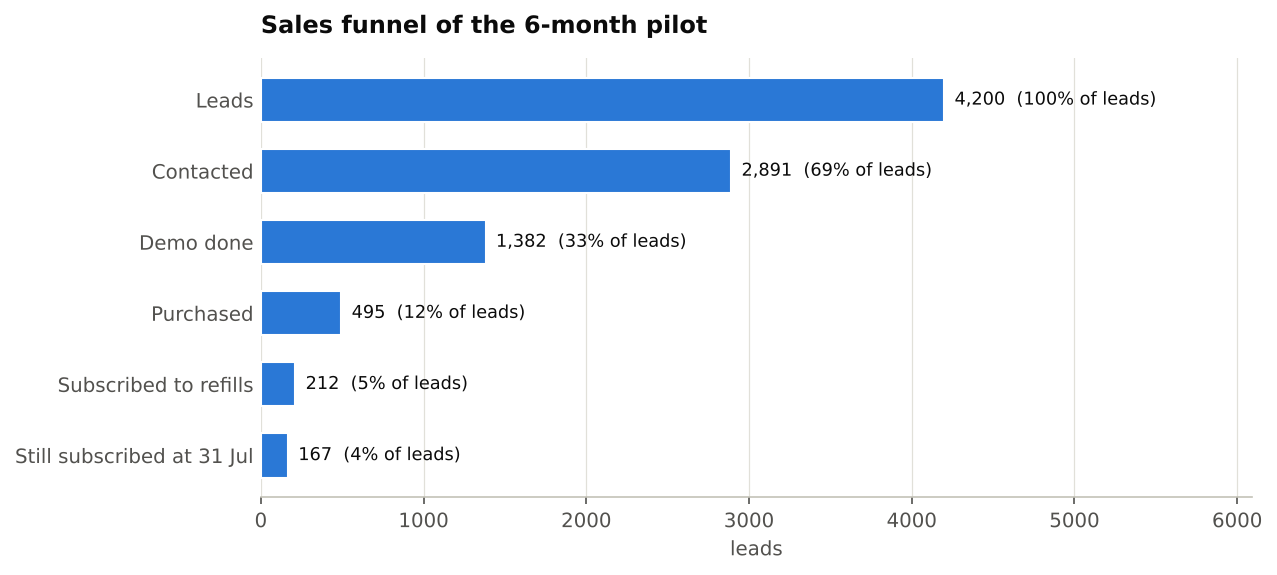

**What it shows.** 4,200 leads → 2,891 contacted (69%) → 1,382 demos (48% of contacted) → 495 buyers (36% of demos) → 212 refill subscribers (43% of buyers). Lead-to-sale: 11.8%.

**Why.** The biggest loss is before the demo: 67% of leads never see the product, mostly low-intent online leads that were not reached or not interested. Once a household has a demo, 36% buy - 3.0x the lead-level rate.

**So what.** The demo is the conversion engine. Sales effort should go into getting more leads to a demo (faster follow-up, society events), not into more top-of-funnel ads.

In [18]:
show(A.p1_funnel(p))

### P2. Leads per month by channel
*Question: How did lead volume and mix change?*

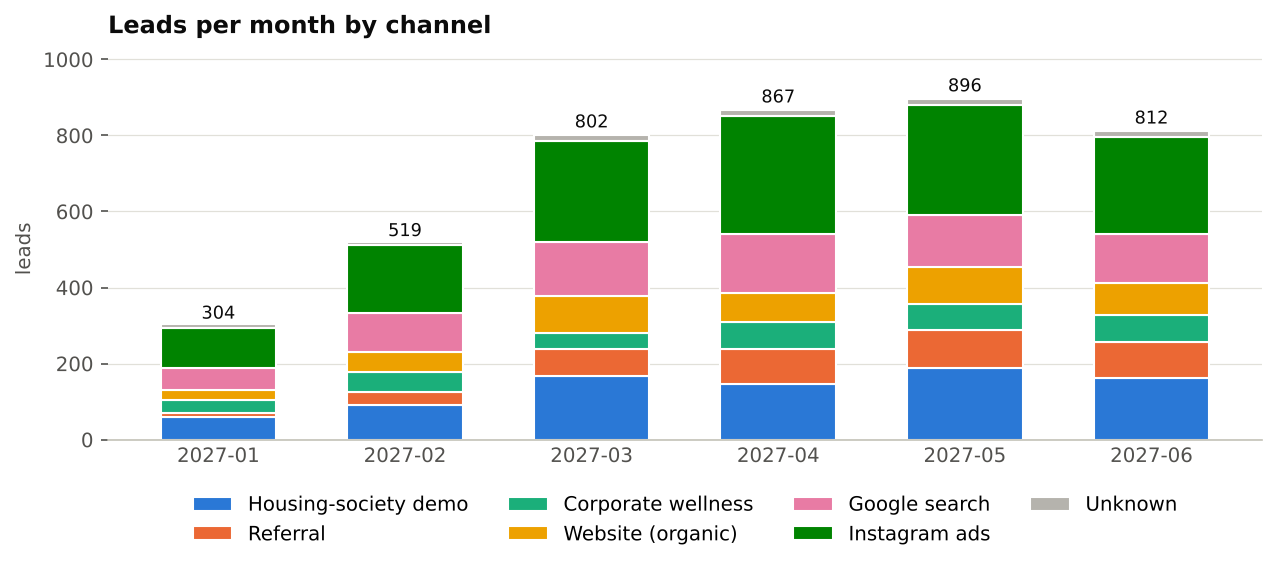

**What it shows.** Leads grew from 304 in 2027-01 to 812 in 2027-06. Referral share went from 3% to 11%; Instagram from 34% to 31%.

**Why.** Paid ads start the pipeline; referrals can only grow once there are happy customers to refer, which is why they build up from month 3. A small 'Unknown' block is leads whose source was not recorded.

**So what.** Referral growth is the healthiest signal in the pilot - it is the cheapest channel (see P4). Recording the source for every lead is a process fix the sales team should make now.

In [19]:
show(A.p2_volume(p))

### P3. Lead-to-purchase rate by channel
*Question: Which channels bring buyers, not just leads?*

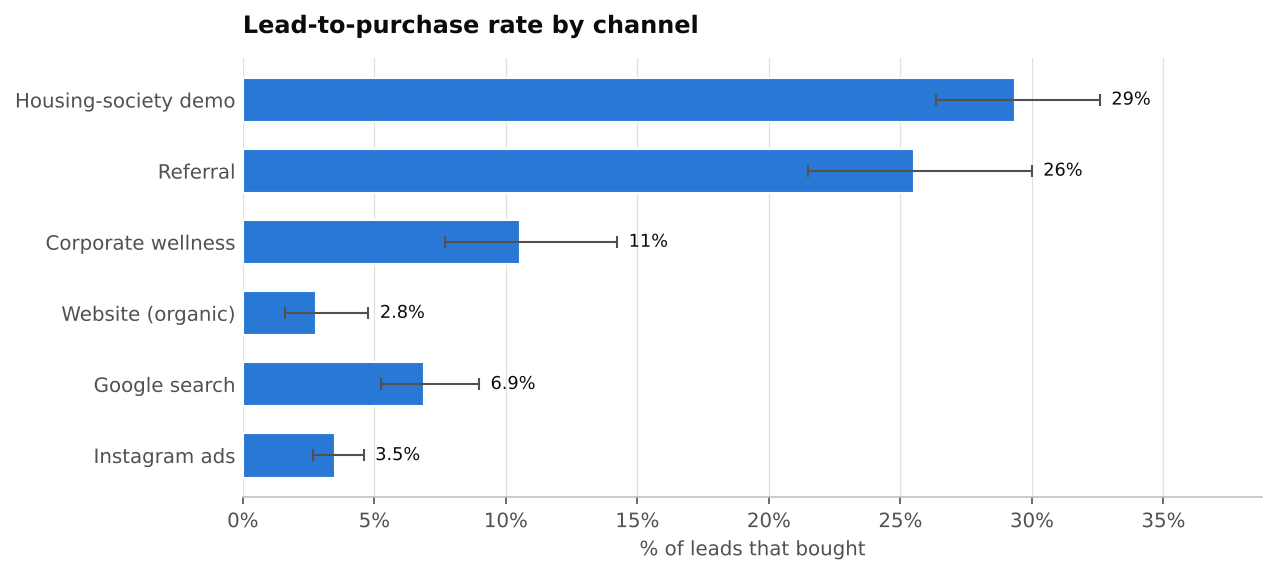

**What it shows.** Share of each channel's leads that bought, with 95% intervals. Best: Housing-society demo 29.4% (239 of 814); worst: Website (organic) 2.8% (12 of 434). The differences between channels are statistically significant (p < 0.001).

**Why.** Society demos and referrals arrive with trust and a chance to see the product; ad and website leads are often a single click with little intent (Instagram: 3.5%). The highest-volume channels are not the best-converting ones.

**So what.** A Website (organic) lead is worth about 11x less than a Housing-society demo lead. Budget should be judged on cost per buyer, not cost per lead (next chart).

In [20]:
show(A.p3_channel_conv(p))

### P4. Cost to acquire one buyer (CAC) by channel
*Question: Which channels are affordable?*

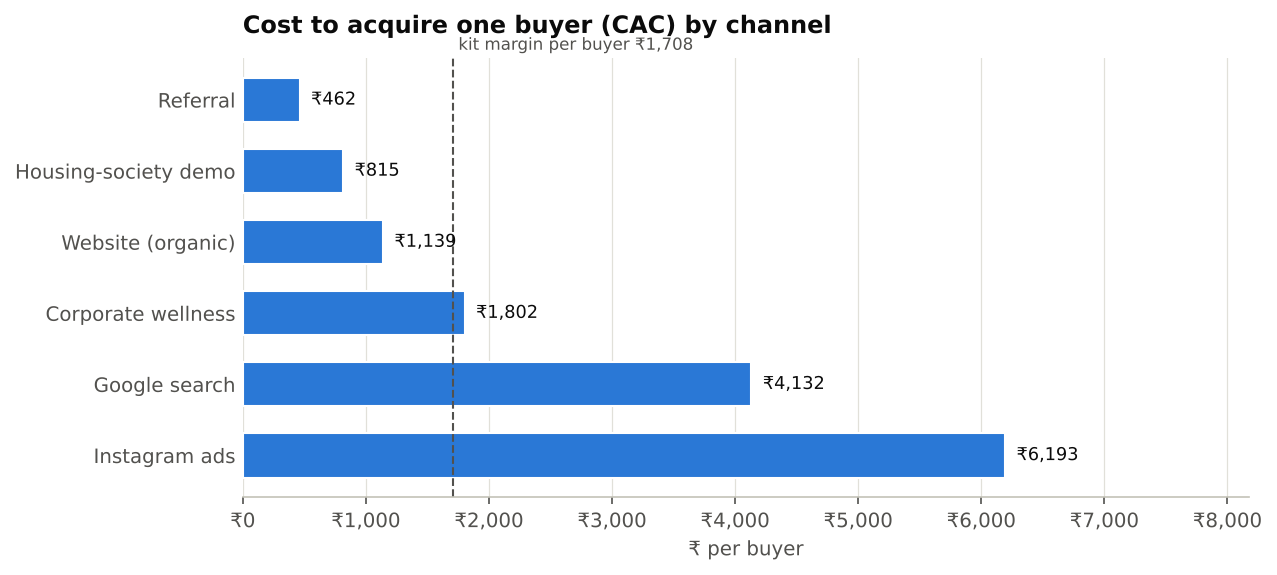

**What it shows.** Marketing spend per channel ÷ buyers from that channel. Blended CAC = ₹1,713. The line marks the average contribution from the first sale (₹1,708 after GST, unit cost, delivery and returns).

**Why.** CAC = cost per lead ÷ lead-to-purchase rate. Instagram ads: ₹217 per lead ÷ 3.5% = ₹6,193; Housing-society demo: ₹239 per lead ÷ 29.4% = ₹815; Referral: ₹118 per lead ÷ 25.5% = ₹462. A cheap lead that rarely buys is an expensive buyer.

**So what.** Channels above the line lose money on the first sale and only pay back if the customer subscribes: Instagram ads, Google search, Corporate wellness. Shift budget from the costliest channels to society demos and referral rewards.

In [21]:
show(A.p4_cac(p))

### P5. What buyers put in the basket
*Question: Do customers buy add-ons?*

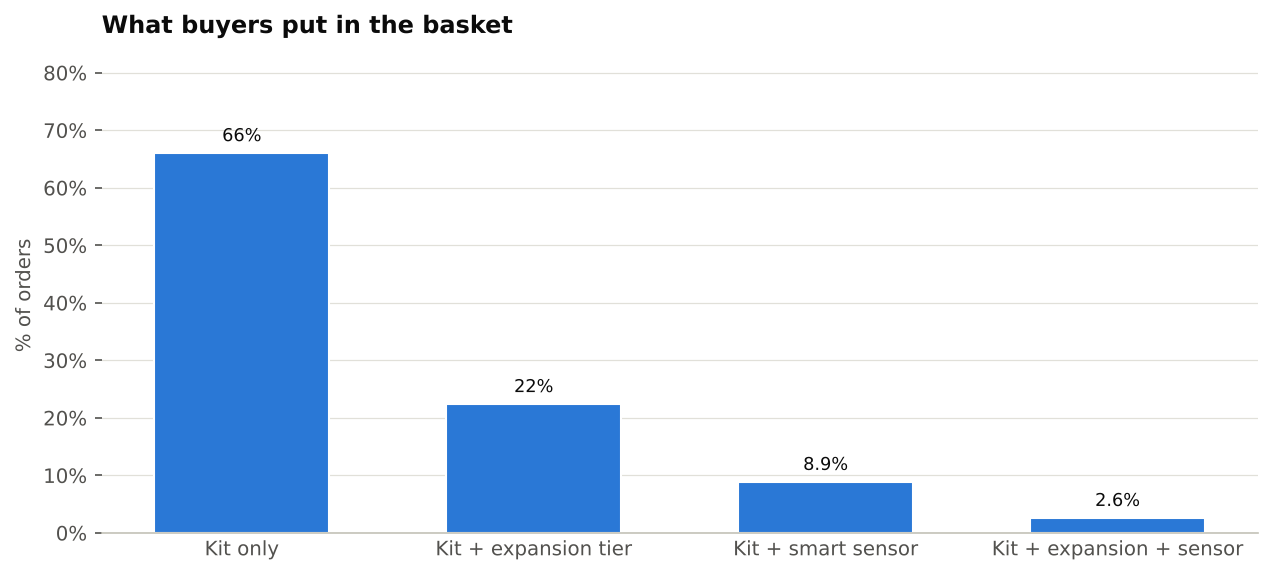

**What it shows.** 495 orders. Average order value ₹5,963 (incl. GST). 66% bought the kit alone; 34% added at least one extra. 15% used a 10% discount.

**Why.** Add-ons follow space: 37% of large-balcony and 26% of terrace buyers took the expansion tier, against 18% with a small balcony.

**So what.** Add-ons lift revenue per buyer at good margin. Offer the expansion tier as a 'grow later' upgrade after the first harvest rather than at checkout, when price resistance is highest.

In [22]:
show(A.p5_basket(p))

## 4. Pilot sales pipeline – diagnostic analytics

### Q1. A/B price test: purchase rate after a demo
*Question: Which launch price works best in the field?*

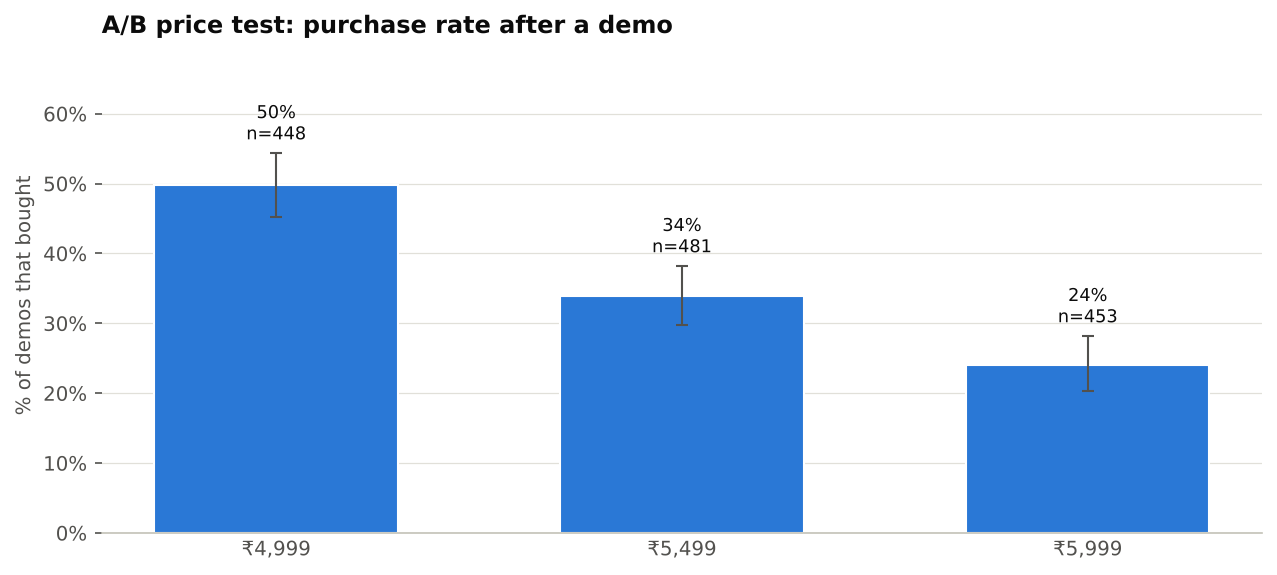

**What it shows.** Leads were randomly offered ₹4,999, ₹5,499 or ₹5,999. After a demo, 50% bought at ₹4,999, 34% at ₹5,499 and 24% at ₹5,999 (statistically significant, p < 0.001).

**Why.** Because price was randomised, the difference is caused by price, not by who saw it. Each ₹500 step loses roughly 13 points of conversion.

**So what.** Kit contribution per demo is highest at ₹4,999 (₹694 per demo). The extra margin from a higher price does not make up for the lost buyers, which also lose future refill income.

In [23]:
show(A.q1_price(p))

### Q2. Purchase rate by speed of first contact
*Question: Does replying fast win more sales?*

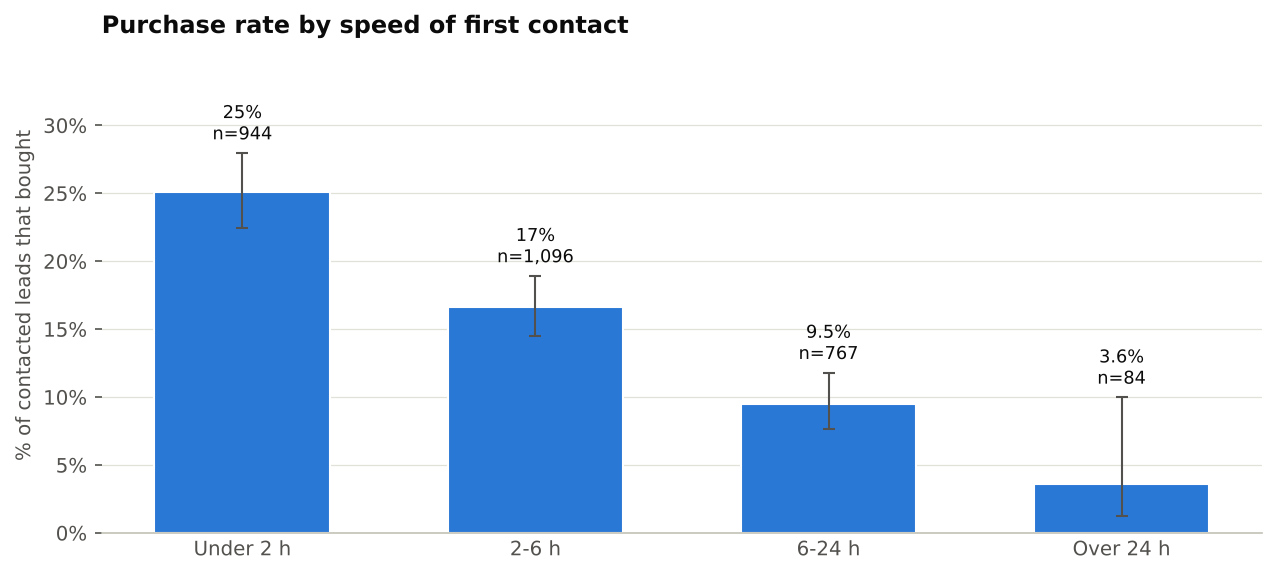

**What it shows.** Of contacted leads, 25.1% bought when called within 2 hours vs 3.6% after more than 24 hours (p < 0.001). 4% of all leads waited more than a day.

**Why.** Interest fades quickly after someone fills in a form; a late call reaches a lead who has moved on or bought elsewhere. Note this is observational - busy reps may also be slower and weaker - but the direction is consistent.

**So what.** Set a 2-hour response target with automatic WhatsApp acknowledgement and lead routing to a free rep. It costs little and lifts conversion across every channel.

In [24]:
show(A.q2_response(p))

### Q3. Demo-to-purchase by sales rep and demo type
*Question: Is conversion about the rep, the format, or both?*

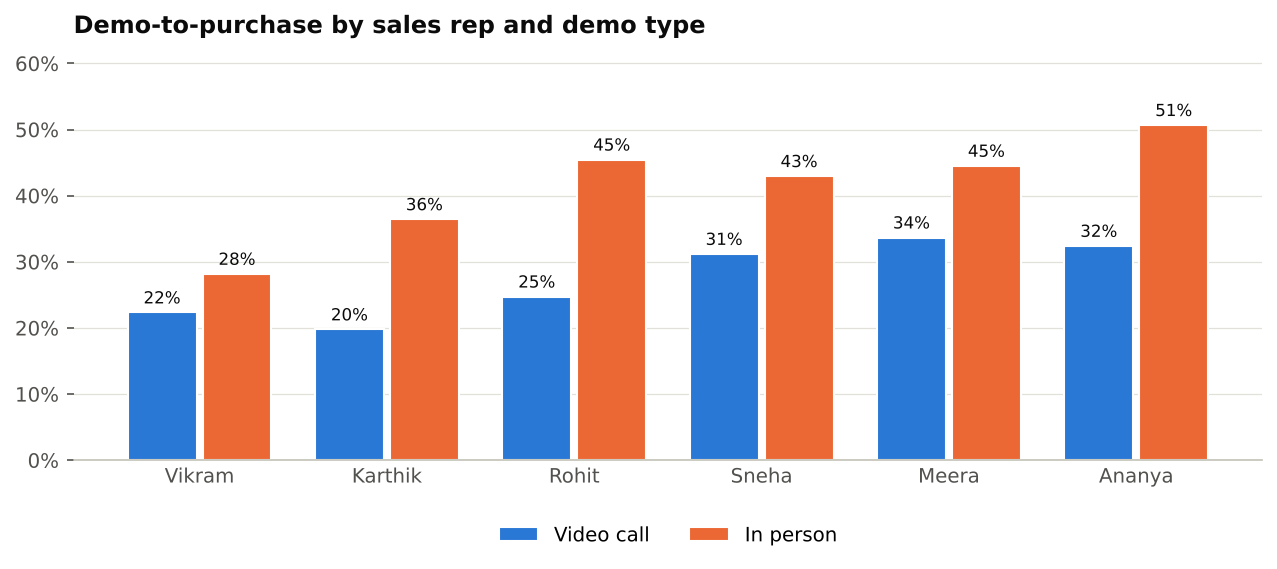

**What it shows.** In-person demos convert 42% vs 28% on video. Across reps, demo conversion ranges from 25% (Vikram) to 43% (Ananya); rep differences are statistically significant (p < 0.001).

**Why.** Touching the product and seeing a live harvest removes the 'will it work for me' doubt. Rep skill adds on top: the best reps beat the weakest in both formats, so it is not just that they got easier leads.

**So what.** Pair the weakest reps with Ananya for shadowing and script the top rep's demo. Push in-person demos where lead density allows (societies); keep video for scattered leads.

In [25]:
show(A.q3_rep(p))

### Q4. What predicts a purchase after a demo?
*Question: Which levers matter most at the close?*

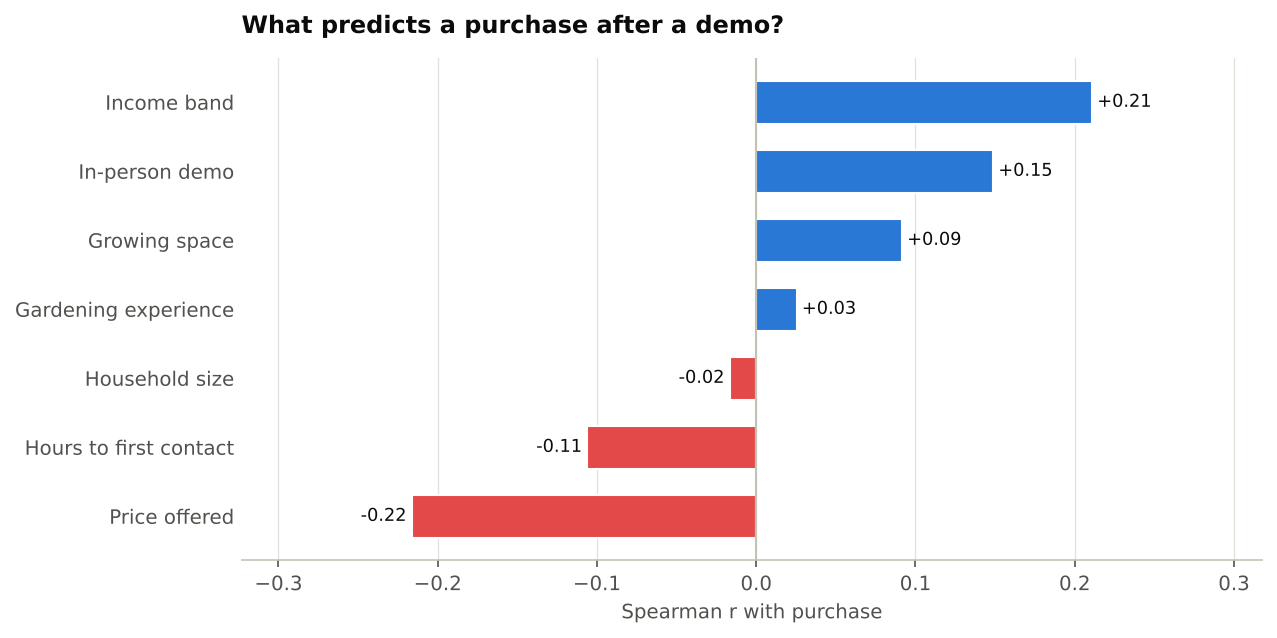

**What it shows.** Rank correlation of each factor with buying, among 1,382 leads who had a demo. Blue raises the chance of purchase, red lowers it.

**Why.** Customer fit (income band) and price are the strongest factors. Household size and experience barely matter once someone has seen a demo. Income is blank for a quarter of leads, so its bar uses fewer rows.

**So what.** Qualify leads on space and income before booking a demo, keep price at the low test point, and demo in person - these three levers are in the company's hands.

In [26]:
show(A.q4_drivers(p))

### Q5. Refill subscribers still active, by speed of first harvest
*Question: What keeps subscribers from cancelling?*

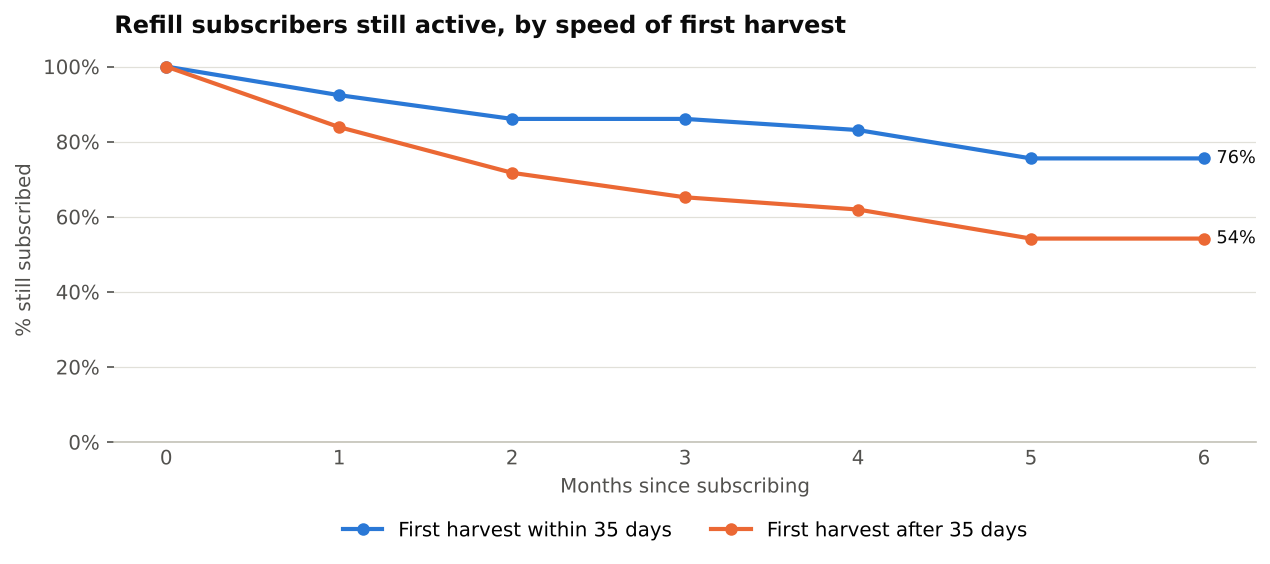

**What it shows.** Kaplan-Meier curve: share of 212 subscribers still paying each month (customers still active at 31 July are counted correctly, not as churners). Overall monthly churn is 9.4%.

**Why.** Subscribers whose first harvest came within 35 days churn at 6.1% a month, against 13.4% for slower starts. An early harvest proves the system works and builds the habit. Onboarding calls help too: 6.5% vs 18.9% monthly churn.

**So what.** The first five weeks decide lifetime value. Ship fast-growing microgreens in the first refill, call every new customer in week 1, and track 'days to first harvest' as the key operating metric.

In [27]:
show(A.q5_retention(p))

### Q6. Customer satisfaction (NPS score) by days to first harvest
*Question: Does a quick first harvest make happier customers?*

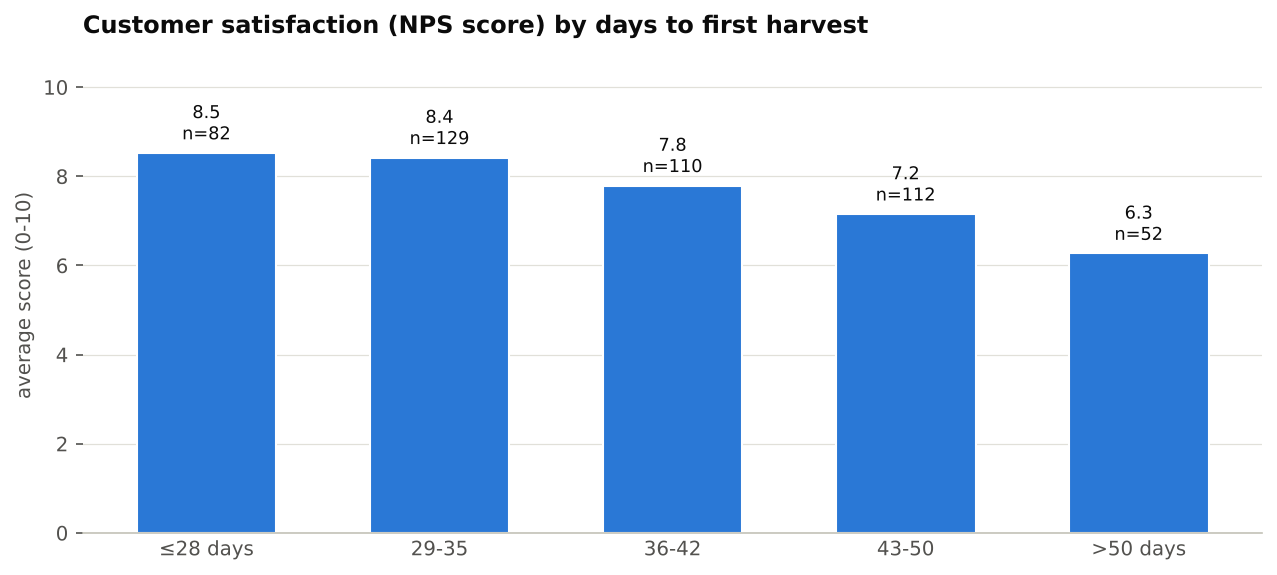

**What it shows.** Average 0-10 recommendation score for 485 buyers, grouped by how long their first harvest took. Spearman r = -0.41 (p < 0.001). Net Promoter Score = 38% promoters − 22% detractors = +16.

**Why.** Satisfaction falls steadily the longer customers wait for something to eat. Promoters create the referrals that proved to be the cheapest channel, so slow harvests also raise future acquisition cost.

**So what.** Faster first harvest improves three numbers at once - churn, NPS and referrals. It is the single most valuable operational fix found in the pilot.

In [28]:
show(A.q6_nps(p))

## 5. End-to-end validation – survey vs pilot
The survey predicts; the pilot measures. Putting them side by side shows which survey findings can be trusted
for planning and by how much they must be corrected.

### E1. Price sensitivity: survey vs pilot (₹4,999 = 100)
*Question: Did the survey predict how buyers react to price?*

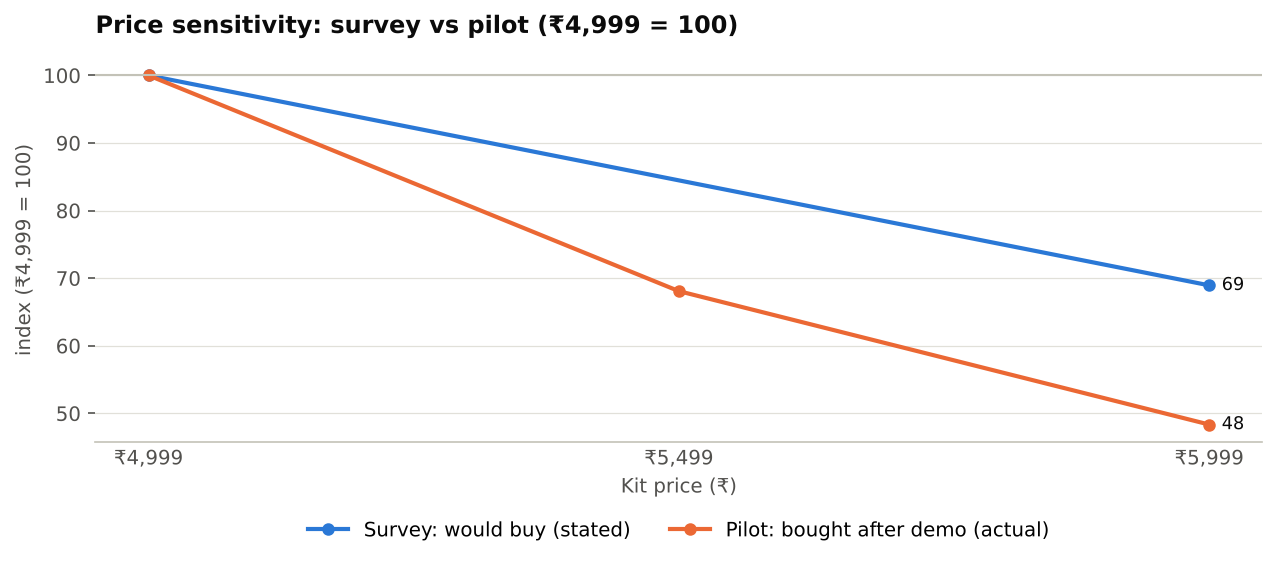

**What it shows.** Both lines are indexed so ₹4,999 = 100, which lets a stated rate and a real rate share one scale. Raising the price to ₹5,999 cut stated intent by 31% in the survey and actual purchases by 52% in the pilot.

**Why.** The survey captured the direction and the rough size of price sensitivity. Real buyers were even more price-sensitive than the survey suggested - spending real money sharpens attention to price.

**So what.** The survey is a reliable guide to price direction, so it can be used to screen future price changes before a field test. The launch price should stay at ₹4,999.

In [29]:
show(A.e1_price_validation(s, p))

### E2. What customers said vs what they did
*Question: How far can survey answers be trusted for the business plan?*

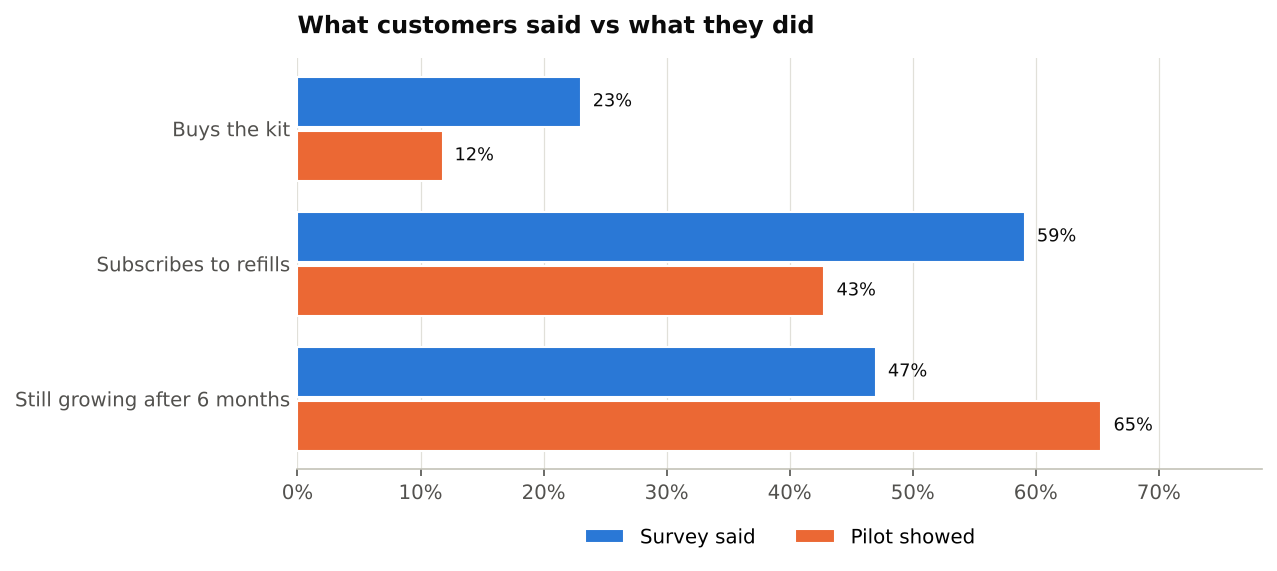

**What it shows.** Three funnel stages measured twice. Buying: 23% said likely vs 11.8% of pilot leads bought (ratio 0.51). Subscribing: 59% vs 43% (ratio 0.72). Six-month survival: 47% vs 65%.

**Why.** A 'likely' in a survey costs nothing, so stated intent overshoots: only about half as many leads bought as survey respondents said they would. Subscription was compared like for like (likely buyers vs actual buyers) and came in at 0.72x stated - close to the 0.70 realism factor used in the earlier business plan. Six-month survival beat past gardening behaviour, so onboarding and refills appear to help people keep going.

**So what.** Use these ratios as correction factors whenever the survey feeds a forecast: subscription intent × 0.72, and never treat top-2-box intent as a purchase rate.

,metric,base,survey %,pilot %,pilot ÷ survey
0,Buys the kit,"% of survey (₹4,999-5,999) / % of pilot leads",23.0,11.8,0.51
1,Subscribes to refills,"% of likely buyers / % of actual buyers, at ₹299",59.1,42.8,0.72
2,Still growing after 6 months,% of triers / % of subscribers,47.0,65.3,1.39


In [30]:
r = A.e2_stated_vs_actual(s, p); show(r)
display(r["table"].assign(survey=lambda x: (x.survey * 100).round(1), pilot=lambda x: (x.pilot * 100).round(1), ratio=lambda x: x.ratio.round(2))
        .rename(columns={"survey": "survey %", "pilot": "pilot %", "ratio": "pilot ÷ survey"}))

### E3. Lifetime value ÷ acquisition cost by channel
*Question: Which channels should the sales pipeline be built on?*

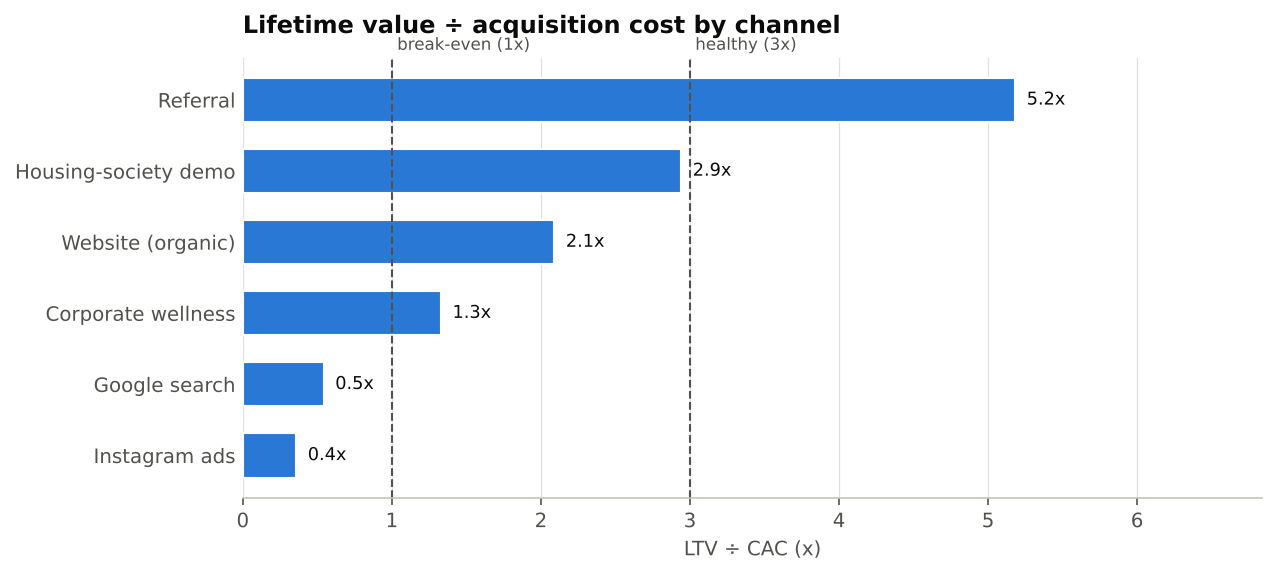

**What it shows.** Customer lifetime value (kit margin + expected refill margin, using the pilot's 9.4% monthly churn and ₹141 margin per box, capped at 24 months) divided by CAC. Above 3x is healthy; below 1x loses money.

**Why.** Lifetime value per buyer is similar across channels (₹2,218 to ₹2,398), so the ranking is driven by CAC: Referral 5.2x; Housing-society demo 2.9x; Website (organic) 2.1x; Corporate wellness 1.3x; Google search 0.5x; Instagram ads 0.4x. Paid search and social buy attention, not intent. The smallest channel has only 12 buyers, so its ratio is uncertain.

**So what.** Build the pipeline on Referral and Housing-society demo. Cut or redesign Instagram ads, Google search.

,channel,LTV ÷ CAC,LTV (₹),CAC (₹),buyers
1,Referral,5.18,2391.0,462.0,102
0,Housing-society demo,2.94,2398.0,815.0,239
3,Website (organic),2.09,2380.0,1139.0,12
2,Corporate wellness,1.33,2395.0,1802.0,36
4,Google search,0.54,2241.0,4132.0,50
5,Instagram ads,0.36,2218.0,6193.0,49


In [31]:
r = A.e3_channel_ltv(p); show(r)
display(r["table"].assign(value=lambda x: x.value.round(2), ltv=lambda x: x.ltv.round(0), cac=lambda x: x.cac.round(0))
        .rename(columns={"label": "channel", "value": "LTV ÷ CAC", "ltv": "LTV (₹)", "cac": "CAC (₹)"}).iloc[::-1])

## 6. The finalised sales pipeline
Each stage of the funnel with the pilot result, the target for the next phase, and the chart that justifies it.

In [32]:
A.pipeline_plan(s, p)

,Stage,Measure,Pilot result,Target / action,Evidence
0,1. Lead capture,Leads / month,700,Shift mix to society demos + referrals,"Channel CAC (P4), LTV:CAC (E3)"
1,2. First contact,Contacted,69%,"90%, called within 2 hours",Purchase rate 25.1% when called < 2 h (Q2)
2,3. Demo,Contacted → demo,48%,In-person where possible,In-person converts better (Q3)
3,4. Close,Demo → purchase,36%,"Hold ₹4,999; coach weaker reps","Price A/B test (Q1), rep spread (Q3)"
4,5. Subscribe,Buyer → refill,43%,Offer at ₹299 with first box free,"Survey ratio (E2), time-poor segment (G7)"
5,6. Retain,Monthly churn,9.4%,Below 6% via first harvest ≤35 days,"Harvest speed + onboarding (Q5, Q6)"


## 7. Key insights
1. **The market is real but narrow.** About one in five survey respondents is positive at the price they saw, and the
   pilot converted 12% of leads. Demand is concentrated in households with a balcony or terrace and ₹1 lakh+ income.
2. **Price is the strongest lever and it was tested properly.** Both the randomised survey price and the field A/B
   test show sharp drops above ₹4,999; the field drop was steeper than the survey predicted. Launch at ₹4,999.
3. **The demo is the conversion engine.** Two thirds of leads never see a demo; those who do buy at about three times
   the average rate, more so in person and when contacted within two hours.
4. **Channel choice decides profitability.** Referrals and housing-society demos acquire buyers for a fraction of
   the cost of Instagram or Google; paid social and search do not pay back over a customer's life.
5. **Retention is won in the first five weeks.** A first harvest within 35 days and an onboarding call roughly halve
   monthly churn and lift satisfaction, which in turn feeds referrals.
6. **Survey answers need correction factors.** Purchase intent overstated actual buying by about half; subscription
   intent by about 30%. Future forecasts should apply these ratios.